# Where interference estimates remain credible

## How Degree and Assignment Probability Shape Positivity

For the rule “at least one assigned neighbor,” a node of degree $d$ has

$$
\pi(0)=(1-p)^d,\qquad \pi(1)=1-(1-p)^d.
$$

The largest inverse probability is

$$
W_{\max}(d,p)=\max\{1/\pi(0),1/\pi(1)\}.
$$

Here, $p$ is the independent assignment probability. Large $W_{\max}$ means that at least one contrasted exposure is rare, so an observed unit in that exposure receives a large contribution.

### Packages and notebook settings

In [ ]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("07_network_interference");
using CSV, TOML, Printf
using RiskLabAI.CausalFactorAnalysis: exposure_mean_contrast
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore, normal_block
include(joinpath("..","support","BookNetworkStudy.jl"))
using .BookNetworkStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter07_random_inputs"),"network")
captions=Dict("mapping_public_provenance"=>"Provenance of the public returns used only to fix a topology.","mapping_public_industries"=>"Selected public industries and descriptive topology degrees.","mapping_public_edges"=>"Edges in the fixed public correlation topology.","mapping_public_graph_summary"=>"Summary of the fixed public correlation topology.","mapping_scope_ledger"=>"Roles and limits of the public and generated inputs.","mapping_definition"=>"Objects in the neighbor-exposure mapping.","mapping_public_assignment"=>"One generated assignment on the fixed public topology.","mapping_public_probabilities"=>"Exact marginal exposure probabilities under independent assignment.","mapping_assignment_contract"=>"Declared generated assignment on the fixed public topology.","mapping_probability_check"=>"Enumeration check for marginal neighbor-exposure probabilities.","mapping_section_summary"=>"Summary of the fixed topology and exposure mapping.","ht_exact_potential_outcomes"=>"Potential outcomes in the released three-unit exact design.","ht_exact_assignments"=>"All assignments in the released three-unit exact design.","ht_exact_summary"=>"Exact randomization expectation for the released exposure contrast.","ht_exact_contributions"=>"Unit contributions for one exact-design assignment.","ht_returned_fields"=>"Quantities returned by the released exposure calculation.","ht_graph_enumeration"=>"Exact exposure-contrast enumeration across four small graphs.","ht_public_generated_design"=>"Generated potential-outcome design on the fixed public topology.","ht_public_exact_summary"=>"Exact design expectations on the fixed public topology.","ht_public_repeated_summary"=>"Repeated generated assignments on the fixed public topology.","ht_public_quantiles"=>"Finite-sample distributions under repeated generated assignments.","ht_public_contributions"=>"Unit contributions under one generated public-topology assignment.","ht_invalid_input_checks"=>"Plain-language checks for invalid exposure calculations.","scope_probability_grid"=>"Exposure probabilities across degree and assignment probability.","scope_probability_grid_selected"=>"Selected positivity cases for the neighbor-exposure rule.","scope_simulation_grid"=>"Finite-sample variation across regular graph designs.","scope_simulation_grid_book"=>"Selected finite-sample results across regular graph designs.","scope_rule_comparison"=>"Comparison of one-neighbor and two-neighbor exposure rules.","scope_public_density_sweep"=>"Generated exposure calculations across descriptive public topologies.","scope_public_density_sweep_book"=>"Readable density and exposure-rarity comparison.","scope_financial_network_context"=>"Permitted interpretation of the financial network comparison.","scope_claim_boundary"=>"Scientific boundaries for the network calculations.","scope_section_summary"=>"Summary of density, positivity, and scope results.");


### Exposure-zero probability

Row,Degree,Assignment probability,Probability of exposure zero,Probability of exposure one,Largest inverse probability
,Int64,Float64,Float64,Float64,Float64
1,2,0.05,0.9025,0.0975,10.2564
2,2,0.1,0.81,0.19,5.26316
3,2,0.25,0.5625,0.4375,2.28571
4,2,0.5,0.25,0.75,4.0
5,4,0.05,0.814506,0.185494,5.39102
6,4,0.1,0.6561,0.3439,2.90782
7,4,0.25,0.316406,0.683594,3.16049
8,4,0.5,0.0625,0.9375,16.0
9,8,0.05,0.66342,0.33658,2.97107


Row,Degree,Assignment probability,Probability of exposure zero,Probability of exposure one,Largest inverse probability
,Int64,Float64,Float64,Float64,Float64
1,2,0.05,0.9025,0.0975,10.2564
2,2,0.25,0.5625,0.4375,2.28571
3,2,0.5,0.25,0.75,4.0
4,8,0.05,0.66342,0.33658,2.97107
5,8,0.25,0.100113,0.899887,9.98872
6,8,0.5,0.00390625,0.996094,256.0
7,12,0.05,0.54036,0.45964,2.17562
8,12,0.25,0.0316764,0.968324,31.5693
9,12,0.5,0.000244141,0.999756,4096.0


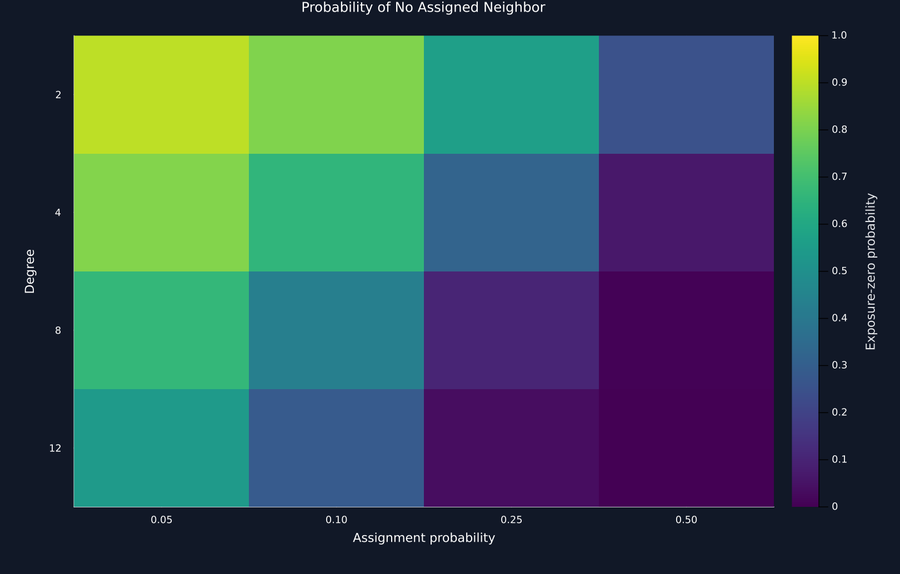

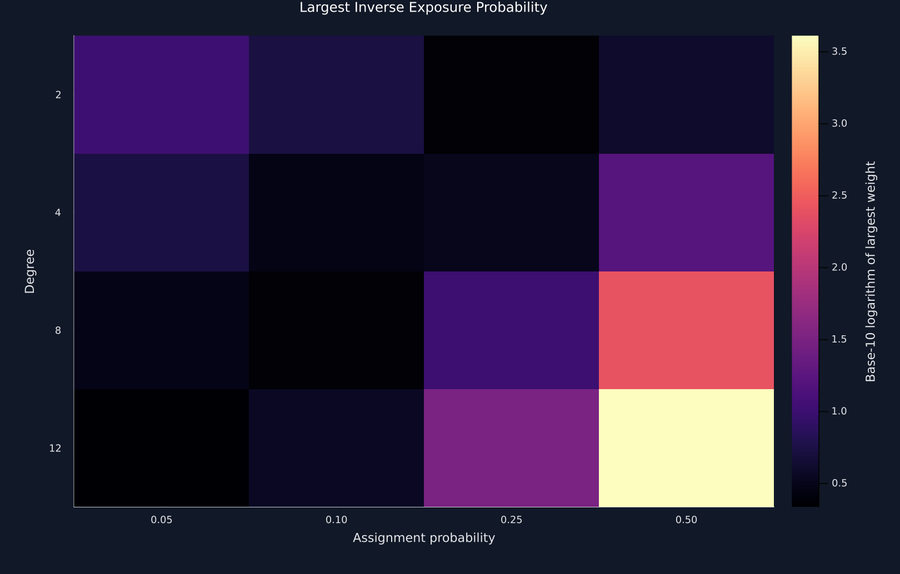

In [1]:
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:cim7-"*replace(name,"_"=>"-"))
    return nothing
end
degrees_grid=[2,4,8,12]
probabilities_grid=[.05,.1,.25,.5]
probability_grid=frame(["Degree","Assignment probability","Probability of exposure zero","Probability of exposure one","Largest inverse probability"],[(degree,probability,p0,1-p0,max(1/p0,1/(1-p0))) for degree in degrees_grid for probability in probabilities_grid for p0 in ((1-probability)^degree,)])
table(probability_grid,"scope_probability_grid")
selected_grid=probability_grid[in.(probability_grid.Degree,Ref([2,8,12])).&in.(probability_grid[:,2],Ref([.05,.25,.5])),:]
table(selected_grid,"scope_probability_grid_selected")
save_data(probability_grid,paths,"scope_probability_heatmap")
matrix_probability=permutedims(reshape(probability_grid[:,3],4,4))
figure=heatmap(1:4,1:4,matrix_probability;xticks=(1:4,[@sprintf("%.2f",p) for p in probabilities_grid]),yticks=(1:4,string.(degrees_grid)),yflip=true,xlabel="Assignment probability",ylabel="Degree",color=:viridis,clims=(0,1),colorbar_title="Exposure-zero probability",title="Probability of No Assigned Neighbor",size=(1080,690))
save_figure(figure,paths,"scope_probability_heatmap")
save_data(probability_grid,paths,"scope_inverse_weight_heatmap")
matrix_weight=permutedims(reshape(probability_grid[:,5],4,4))
figure=heatmap(1:4,1:4,log10.(matrix_weight);xticks=(1:4,[@sprintf("%.2f",p) for p in probabilities_grid]),yticks=(1:4,string.(degrees_grid)),yflip=true,xlabel="Assignment probability",ylabel="Degree",color=:magma,colorbar_title="Base-10 logarithm of largest weight",title="Largest Inverse Exposure Probability",size=(1080,690))
plot!(figure;showaxis=true,foreground_color_text=palette.text,foreground_color_guide=palette.text)
save_figure(figure,paths,"scope_inverse_weight_heatmap")


## Finite-Sample Variation Under Different Exposure Rules

For a threshold $r$, define exposure by

$$
D_i^{(r)}(Z)=\mathbf 1\!\left\{\sum_j A_{ij}Z_j\geq r\right\}.
$$

The case $r=1$ requires one assigned neighbor. The case $r=2$ requires at least two. Raising the threshold can make exposure one rare even when every marginal probability remains positive. The resulting increase in finite-sample variation is a property of the declared design and mapping.

### Graph structure and path checks

In [2]:
simulation_random_state=7301
simulation_repetitions=2500
simulation_rows=[]
all_regular_rows=[]
for radius in [1,2,4,6]
    graph=ring_graph(40,radius)
    degree=sum(graph[1,:])
    baseline=.5 .+.2 .*sin.(collect(0:39)./3)
    effects=.6 .+.1 .*cos.(collect(0:39)./5)
    truth=mean(effects)
    for probability in probabilities_grid
        exposure_probability=exposure_probabilities(graph,probability)
        assignments=normal_block(store,"regular_"*string(radius)*"_"*string(round(Int,probability*100)))
        simulation=network_estimates(graph,baseline,effects,probability,assignments)
        estimates=simulation[:,3]
        push!(simulation_rows,(degree,probability,truth,mean(estimates),std(estimates),sqrt(mean(abs2,estimates.-truth)),1/minimum(exposure_probability)))
        for row in eachrow(simulation)
            push!(all_regular_rows,(radius,degree,probability,row[1],row[2],row[3]))
        end
    end
end
simulation_grid=frame(["Degree","Assignment probability","Known effect","Mean estimate","Standard deviation","Root mean squared error","Largest inverse probability"],simulation_rows)
table(simulation_grid,"scope_simulation_grid")
simulation_grid_book=simulation_grid[in.(simulation_grid.Degree,Ref([2,12])).&in.(simulation_grid[:,2],Ref([.05,.25,.5])),["Degree","Assignment probability","Mean estimate","Standard deviation","Root mean squared error","Largest inverse probability"]]
table(simulation_grid_book,"scope_simulation_grid_book")
all_regular=frame(["Radius","Degree","Assignment probability","Repetition","Exposed units","Estimate"],all_regular_rows)
save_data(all_regular,paths,"scope_all_regular_estimates")
rule_rows=[]
all_rule_rows=[]
rule_graph=ring_graph(40,2)
rule_degree=sum(rule_graph[1,:])
rule_baseline=.5 .+.2 .*sin.(collect(0:39)./3);


Row,Degree,Assignment probability,Known effect,Mean estimate,Standard deviation,Root mean squared error,Largest inverse probability
,Int64,Float64,Float64,Float64,Float64,Float64,Float64
1,2,0.05,0.613758,0.643934,0.814001,0.814398,10.2564
2,2,0.1,0.613758,0.617405,0.572033,0.571931,5.26316
3,2,0.25,0.613758,0.610429,0.371618,0.371558,2.28571
4,2,0.5,0.613758,0.61874,0.30894,0.308919,4.0
5,4,0.05,0.613758,0.601523,0.814891,0.81482,5.39102
6,4,0.1,0.613758,0.631563,0.573293,0.573455,2.90782
7,4,0.25,0.613758,0.622012,0.429792,0.429785,3.16049
8,4,0.5,0.613758,0.626487,0.511052,0.511109,16.0
9,8,0.05,0.613758,0.596294,0.82754,0.827559,2.97107


Row,Degree,Assignment probability,Mean estimate,Standard deviation,Root mean squared error,Largest inverse probability
,Int64,Float64,Float64,Float64,Float64,Float64
1,2,0.05,0.643934,0.814001,0.814398,10.2564
2,2,0.25,0.610429,0.371618,0.371558,2.28571
3,2,0.5,0.61874,0.30894,0.308919,4.0
4,12,0.05,0.636694,0.857472,0.857608,2.17562
5,12,0.25,0.569734,1.18038,1.18097,31.5693
6,12,0.5,0.745398,5.35811,5.35866,4096.0


### Finite-Sample Variation Across Regular Graphs

Row,Required assigned neighbors,Assignment probability,Probability of exposure one,Largest inverse probability,Mean estimate,Standard deviation,Root mean squared error
,Int64,Float64,Float64,Float64,Float64,Float64,Float64
1,1,0.05,0.185494,5.39102,0.606812,0.79642,0.796291
2,1,0.1,0.3439,2.90782,0.614412,0.581027,0.580911
3,1,0.25,0.683594,3.16049,0.610089,0.417196,0.417128
4,1,0.5,0.9375,16.0,0.605631,0.526093,0.526051
5,2,0.05,0.0140188,71.333,0.613112,2.22018,2.21974
6,2,0.1,0.0523,19.1205,0.61944,1.22477,1.22454
7,2,0.25,0.261719,3.8209,0.622695,0.616043,0.615985
8,2,0.5,0.6875,3.2,0.605539,0.427562,0.427556


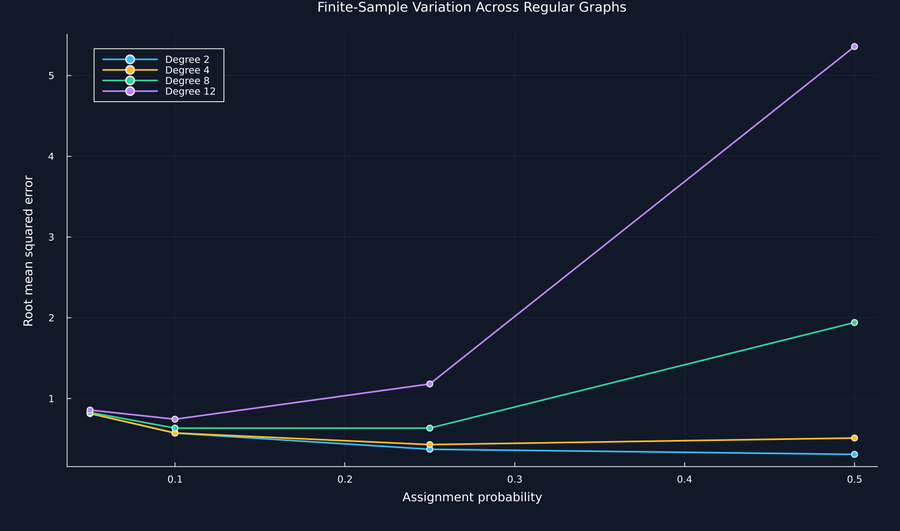

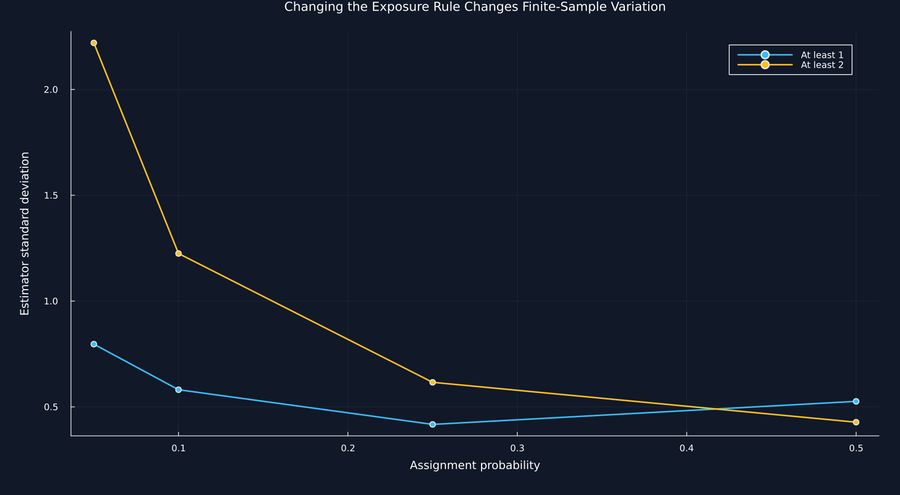

In [2]:
rule_effects=.6 .+.1 .*cos.(collect(0:39)./5)
rule_truth=mean(rule_effects)
for threshold in [1,2]
    for probability in probabilities_grid
        exposure_probability=exposure_probabilities(rule_graph,probability,threshold)
        assignments=normal_block(store,"rule_"*string(threshold)*"_"*string(round(Int,probability*100)))
        simulation=network_estimates(rule_graph,rule_baseline,rule_effects,probability,assignments;threshold)
        estimates=simulation[:,3]
        push!(rule_rows,(threshold,probability,exposure_probability[1,2],1/minimum(exposure_probability),mean(estimates),std(estimates),sqrt(mean(abs2,estimates.-rule_truth))))
        for row in eachrow(simulation)
            push!(all_rule_rows,(threshold,probability,row[1],row[2],row[3]))
        end
    end
end
rule_comparison=frame(["Required assigned neighbors","Assignment probability","Probability of exposure one","Largest inverse probability","Mean estimate","Standard deviation","Root mean squared error"],rule_rows)
table(rule_comparison,"scope_rule_comparison")
all_rule=frame(["Required assigned neighbors","Assignment probability","Repetition","Exposed units","Estimate"],all_rule_rows)
save_data(all_rule,paths,"scope_all_rule_estimates")
save_data(simulation_grid,paths,"scope_rmse_grid")
figure=plot(;xlabel="Assignment probability",ylabel="Root mean squared error",title="Finite-Sample Variation Across Regular Graphs",size=(1100,650),legend=:topleft)
for (degree,color) in zip(degrees_grid,[palette.cyan,palette.amber,palette.green,"#C084FC"])
    group=simulation_grid[simulation_grid.Degree.==degree,:]
    plot!(figure,group[:,2],group[:,6];color,marker=:circle,label="Degree "*string(degree))
end
save_figure(figure,paths,"scope_rmse_grid")
save_data(rule_comparison,paths,"scope_rule_comparison")
figure=plot(;xlabel="Assignment probability",ylabel="Estimator standard deviation",title="Changing the Exposure Rule Changes Finite-Sample Variation",size=(1180,650))
for (threshold,color) in [(1,palette.cyan),(2,palette.amber)]
    group=rule_comparison[rule_comparison[:,1].==threshold,:]
    plot!(figure,group[:,2],group[:,6];color,marker=:circle,label="At least "*string(threshold))
end
save_figure(figure,paths,"scope_rule_comparison")


## Separating network description from causal scope

Let $m$ be the number of undirected edges among $N$ nodes. Graph density is

$$
\rho=\frac{2m}{N(N-1)}.
$$

The quantity $\rho$ describes how many possible links are present. It does not state why the links exist or whether a shock travels along them. The public correlation graph is used only to compare fixed topologies under generated assignments and outcomes.

Row,Selected neighbors per node,Undirected edges,Density,Minimum degree,Maximum degree,Smallest exposure probability,Largest inverse probability,Mean estimate,Standard deviation,Error from truth
,Int64,Float64,Float64,Int64,Int64,Float64,Float64,Float64,Float64,Float64
1,1,9.0,0.136364,1,3,0.25,4.0,0.597289,1.03783,-0.00271054
2,2,16.0,0.242424,2,4,0.316406,3.16049,0.594962,1.07052,-0.0050381
3,3,24.0,0.363636,3,6,0.177979,5.61866,0.604246,1.25617,0.00424615
4,4,29.0,0.439394,4,7,0.133484,7.49154,0.601824,1.36094,0.00182393
5,5,35.0,0.530303,5,10,0.0563135,17.7577,0.64123,1.54383,0.0412297


Row,Selected neighbors per node,Undirected edges,Density,Smallest exposure probability,Largest inverse probability,Standard deviation
,Int64,Float64,Float64,Float64,Float64,Float64
1,1,9.0,0.136364,0.25,4.0,1.03783
2,2,16.0,0.242424,0.316406,3.16049,1.07052
3,3,24.0,0.363636,0.177979,5.61866,1.25617
4,4,29.0,0.439394,0.133484,7.49154,1.36094
5,5,35.0,0.530303,0.0563135,17.7577,1.54383


Row,Statement,Status
,String,String
1,Denser links can absorb sufficiently small shocks in the cited model,Model specific
2,Denser links can propagate sufficiently large shocks in the cited model,Model specific
3,The public return graph proves either mechanism,Not supported
4,A correlation edge identifies a causal spillover,Not supported


Row,Question,Answer
,String,String
1,Is the exposure mapping learned from returns?,"No, it is supplied"
2,Are assignments observed in the archive?,"No, they are generated"
3,Are potential outcomes observed in the archive?,"No, they are generated"
4,Does an edge establish a spillover?,No
5,Is a variance or confidence interval returned?,No


Row,Result,Value
,String,String
1,Degree and assignment probability,Determine marginal exposure probabilities
2,Rare exposure,Creates large inverse-probability contributions
3,Exposure threshold,Changes both the estimand and finite-sample variation
4,Public graph,Supplies topology only
5,Financial shock comparison,Retained only as a cited model-specific result


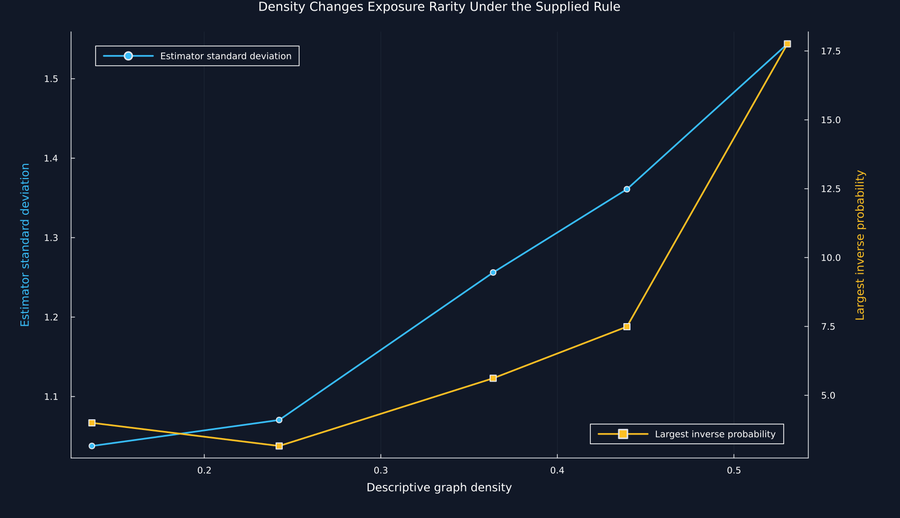

In [3]:
dates,all_industries,public_returns=network_returns()
selected_returns=public_returns[:,1:12]
correlation=cor(selected_returns)
industries=all_industries[1:12]
density_rows=[]
all_density_rows=[]
for neighbor_count in 1:5
    graph=correlation_graph(correlation,neighbor_count)
    degree=vec(sum(graph;dims=2))
    probability=.25
    exposure_probability=exposure_probabilities(graph,probability)
    baseline=.4 .+.08 .*collect(0:11)
    effects=fill(.6,12)
    truth=mean(effects)
    assignments=normal_block(store,"density_"*string(neighbor_count))
    simulation=network_estimates(graph,baseline,effects,probability,assignments)
    estimates=simulation[:,3]
    push!(density_rows,(neighbor_count,sum(graph)/2,sum(graph)/(12*11),minimum(degree),maximum(degree),minimum(exposure_probability),1/minimum(exposure_probability),mean(estimates),std(estimates),mean(estimates)-truth))
    for row in eachrow(simulation)
        push!(all_density_rows,(neighbor_count,row[1],row[2],row[3]))
    end
end
density_sweep=frame(["Selected neighbors per node","Undirected edges","Density","Minimum degree","Maximum degree","Smallest exposure probability","Largest inverse probability","Mean estimate","Standard deviation","Error from truth"],density_rows)
table(density_sweep,"scope_public_density_sweep")
density_sweep_book=density_sweep[:,["Selected neighbors per node","Undirected edges","Density","Smallest exposure probability","Largest inverse probability","Standard deviation"]]
table(density_sweep_book,"scope_public_density_sweep_book")
all_density=frame(["Selected neighbors per node","Repetition","Exposed units","Estimate"],all_density_rows)
save_data(all_density,paths,"scope_all_density_estimates")
financial_context = frame(["Statement","Status"],[["Denser links can absorb sufficiently small shocks in the cited model","Model specific"],["Denser links can propagate sufficiently large shocks in the cited model","Model specific"],["The public return graph proves either mechanism","Not supported"],["A correlation edge identifies a causal spillover","Not supported"]])
table(financial_context,"scope_financial_network_context")
claim_boundary = frame(["Question","Answer"],[["Is the exposure mapping learned from returns?","No, it is supplied"],["Are assignments observed in the archive?","No, they are generated"],["Are potential outcomes observed in the archive?","No, they are generated"],["Does an edge establish a spillover?","No"],["Is a variance or confidence interval returned?","No"]])
table(claim_boundary,"scope_claim_boundary")
section_summary = frame(["Result","Value"],[["Degree and assignment probability","Determine marginal exposure probabilities"],["Rare exposure","Creates large inverse-probability contributions"],["Exposure threshold","Changes both the estimand and finite-sample variation"],["Public graph","Supplies topology only"],["Financial shock comparison","Retained only as a cited model-specific result"]])
table(section_summary,"scope_section_summary")
save_data(density_sweep,paths,"scope_public_density_sweep")
figure=plot(density_sweep.Density,density_sweep[:,9];color=palette.cyan,marker=:circle,linewidth=2.2,label="Estimator standard deviation",xlabel="Descriptive graph density",ylabel="Estimator standard deviation",yguidefontcolor=palette.cyan,title="Density Changes Exposure Rarity Under the Supplied Rule",size=(1180,680),legend=:topleft,right_margin=15Plots.mm)
right=twinx(figure)
plot!(right,density_sweep.Density,density_sweep[:,7];color=palette.amber,marker=:square,linewidth=2.2,label="Largest inverse probability",ylabel="Largest inverse probability",yguidefontcolor=palette.amber,legend=:bottomright,grid=false)
save_figure(figure,paths,"scope_public_density_sweep")
